In [3]:
print('hello')

hello


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("clean.csv")

target = "bad_flg_90plus_24m"
leaky = ["consumer_bad_flg_90plus_24m", "bal_12m", "bal_24m", "line_12m", "line_24m"]

X = pd.get_dummies(df.drop(columns=[target] + leaky), columns=["Acct12"], dtype=int)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape)    # should be (239170, 59)

(239170, 59)


# Building Linear Regression Model

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

logreg = make_pipeline(SimpleImputer(strategy="median"),
                       StandardScaler(),
                       LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

prob_lr = logreg.predict_proba(X_test)[:, 1]
print("Logistic AUC:", roc_auc_score(y_test, prob_lr))

Logistic AUC: 0.8643531654568755


# Building Random Forest Model

In [7]:
from sklearn.ensemble import RandomForestClassifier

rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestClassifier(n_estimators=200, min_samples_leaf=50,
                                          n_jobs=-1, random_state=42))
rf.fit(X_train, y_train)

prob_rf = rf.predict_proba(X_test)[:, 1]
print("Random forest AUC:", roc_auc_score(y_test, prob_rf))

Random forest AUC: 0.8659114998606974


In [8]:
results = pd.DataFrame({
    "actual_default": y_test.values,
    "risk_score_logistic": (prob_lr * 100).round(1),
    "risk_score_forest": (prob_rf * 100).round(1),
})
results.head(10)

,actual_default,risk_score_logistic,risk_score_forest
0,0,4.9,3.9
1,0,1.0,1.3
2,0,34.2,27.2
3,1,17.4,20.1
4,0,12.0,9.8
5,0,17.6,18.0
6,0,1.8,2.2
7,0,2.5,2.7
8,0,2.0,2.6
9,0,5.3,4.8


# Above: Using model to see if someone defaulted comparing to our risk scores from the models 

# Below: Testing whether the scores can be trusted through making 10 equal groups from safest to riskiest

In [9]:
results["group"] = pd.qcut(results["risk_score_forest"], 10, duplicates="drop")
print(results.groupby("group", observed=True)
             .agg(avg_score=("risk_score_forest", "mean"),
                  actual_default_pct=("actual_default", lambda s: s.mean() * 100)))

               avg_score  actual_default_pct
group                                       
(-0.001, 0.2]   0.136935            0.165153
(0.2, 0.4]      0.344264            0.270664
(0.4, 0.8]      0.631898            0.367647
(0.8, 1.4]      1.128000            1.042654
(1.4, 2.4]      1.912921            1.437588
(2.4, 4.0]      3.210388            2.617124
(4.0, 6.3]      5.117270            4.578066
(6.3, 10.4]     8.155599            7.736681
(10.4, 18.8]   14.202189           14.211147
(18.8, 63.5]   28.327973           30.748528


# Below: Finding what was important inside the random forest model

In [10]:
importance = pd.Series(rf[-1].feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.head(10))

Score1    0.220100
Score2    0.196604
Acct7     0.074282
Col1      0.052483
Acct1     0.052428
Util3     0.047939
Inq1      0.037389
Acct5     0.031055
Del1      0.030643
CO1       0.025364
dtype: float64


Below: Finding what was important inside the logistic regression model

In [12]:
coefs = pd.Series(logreg[-1].coef_[0], index=X.columns)

top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
print(top)

Score1      -0.760039
Score2      -0.515460
Acct10      -0.300285
Acct1       -0.159227
Acct12_NU   -0.137044
Inq1         0.127118
Util3        0.126047
Acct12_DV   -0.100420
Acct2        0.095874
Acct4        0.073450
dtype: float64


# Determining what Interest Rate and Loss Rate to pick

In [14]:
import numpy as np

cutoff_%               10.00
approved_%             79.40
default_rate_%          2.17
profit            7209833.00
Name: 8, dtype: float64
Profit if you approve everyone: 6270130


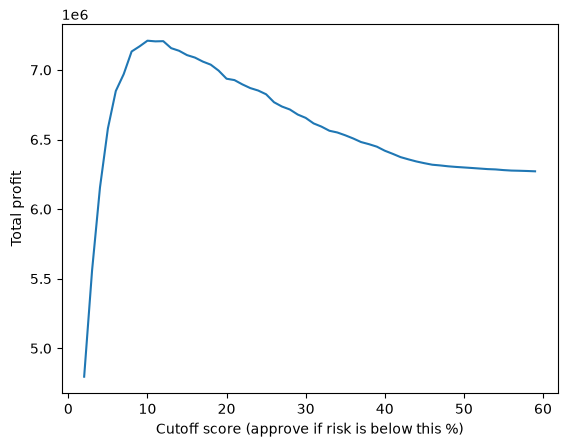

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# ASSUMPTIONS: change these to match your case materials
interest_rate = 0.15
loss_rate = 1.00

prob = prob_rf          # or prob_lr
test_rows = df.loc[y_test.index]

res = pd.DataFrame({
    "prob": prob,
    "default": y_test.values,
    "balance": test_rows["bal_12m"].values,
})
res["profit"] = np.where(res["default"] == 0,
                         res["balance"] * interest_rate,
                         -res["balance"] * loss_rate)

rows = []
for cutoff in np.arange(0.02, 0.60, 0.01):
    approved = res[res["prob"] < cutoff]
    rows.append({"cutoff_%": round(cutoff * 100),
                 "approved_%": round(len(approved) / len(res) * 100, 1),
                 "default_rate_%": round(approved["default"].mean() * 100, 2),
                 "profit": round(approved["profit"].sum())})
table = pd.DataFrame(rows)

print(table.loc[table["profit"].idxmax()])
print("Profit if you approve everyone:", round(res["profit"].sum()))

plt.plot(table["cutoff_%"], table["profit"])
plt.xlabel("Cutoff score (approve if risk is below this %)")
plt.ylabel("Total profit")
plt.show()

In [17]:
rows = []
for ir in [0.10, 0.15, 0.20, 0.25]:
    for ls in [0.5, 0.8, 1.0]:
        profit = np.where(res["default"] == 0, res["balance"] * ir, -res["balance"] * ls)
        best_cut, best_profit = None, None
        for cutoff in np.arange(0.02, 0.60, 0.01):
            total = profit[res["prob"].values < cutoff].sum()
            if best_profit is None or total > best_profit:
                best_cut, best_profit = cutoff, total
        approved = (res["prob"] < best_cut).mean() * 100
        rows.append((ir, ls, round(best_cut * 100), round(approved, 1)))

print(pd.DataFrame(rows, columns=["interest", "loss", "best_cutoff_%", "approved_%"]))

    interest  loss  best_cutoff_%  approved_%
0       0.10   0.5             12        82.5
1       0.10   0.8             10        79.4
2       0.10   1.0              8        75.1
3       0.15   0.5             24        93.8
4       0.15   0.8             12        82.5
5       0.15   1.0             10        79.4
6       0.20   0.5             25        94.4
7       0.20   0.8             18        89.3
8       0.20   1.0             12        82.5
9       0.25   0.5             28        95.9
10      0.25   0.8             24        93.8
11      0.25   1.0             18        89.3
